<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/05_Malware_Detection/QNN_SupplyChainClaMP_Akter2022.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# QNN versus NN on the ClaMP software-supply-chain dataset: Akter et al. (2022) step by step

This notebook re-implements, runs and checks the method of

> Mst Shapna Akter, Md Jobair Hossain Faruk, Nafisa Anjum, Mohammad Masum, Hossain Shahriar, Akond Rahman, Fan Wu and
> Alfredo Cuzzocrea, "Software Supply Chain Vulnerabilities Detection in Source Code: Performance Comparison between
> Traditional and Quantum Machine Learning Algorithms", *2022 IEEE International Conference on Big Data (Big Data)*,
> Osaka, 2022, pp. 5639-5645. https://doi.org/10.1109/BigData55660.2022.10020813

The paper publishes no code. Everything below is written from its method section, which describes the quantum model as the
standard TensorFlow-Quantum (TFQ) "MNIST" tutorial pipeline applied to 16 principal components: classical data encoded as
circuits, a "two-layer model circuit" wrapped in a TFQ-Keras model, hinge loss with labels in {-1, +1}, Adam, 100 epochs.
TFQ is no longer maintained and does not install on a current Python, so the circuit is rebuilt gate by gate in **PennyLane**
(the framework the paper's abstract names) and simulated on 17 qubits.

**What the notebook does.** It downloads the ClaMP *Integrated* dataset (5,210 Windows PE files, 69 header features), reproduces
the paper's preprocessing (shuffle, one-hot encoding of the packer type, standardisation, PCA to 16 components), cuts the file
into the paper's 20 *proportions* (5 %, 10 %, ..., 100 % of the rows), and for every proportion trains the paper's quantum
neural network (QNN) and a classical neural network (NN) and reports precision, recall, F1, accuracy and execution time as the
paper's Tables 1 and 2 do. Two classical baselines (random forest, RBF-SVM) are trained on the identical inputs, every run is
repeated over several seeds, and the last section puts the paper's 160 numbers next to ours with a verdict per claim.

One technical point makes the full protocol affordable on a laptop. The TFQ-tutorial circuit (X-encoded data qubits, one XX
layer and one ZZ layer into a readout qubit) has an **exact closed form**: its read-out is a product of 16 complex numbers. The
notebook derives that formula, checks it against the 17-qubit PennyLane simulation (outputs *and* gradients agree to 1e-8, and
training through the simulator and through the formula gives the same parameters step for step), and then uses the formula to
run all 20 proportions for the paper's 100 epochs. The simulator itself is trained on the smaller proportions so the cost of the
"real" quantum simulation is measured, not guessed.

**How to run it.** Open in Colab (badge above), choose a CPU runtime, and use *Runtime -> Run all*. The first cell installs a
pinned PennyLane; if Colab asks to restart the session, restart and run all again. Nothing needs a GPU or a quantum account.

**Runtime.** With `FAST_MODE = True` (4 of the 20 proportions, 2 seeds, the simulator trained on the 5 % slice for 2 epochs)
the notebook runs in about 6 minutes on a laptop CPU (expect about 10 minutes on a Colab CPU). With `FAST_MODE = False` (all
20 proportions, 100 epochs, 3 seeds, the simulator trained on the 5 %, 10 % and 25 % slices for 2 epochs) it took
59 min on the validation machine (a shared laptop CPU). The committed notebook contains the outputs of the run named in
the configuration cell.

**What you get at the end.** The paper's Tables 1 and 2 re-computed, accuracy- and time-versus-proportion curves with the paper's
values overlaid, the QNN's loss curves, confusion matrices with malware as the positive class, a measured simulator-versus-formula
cost, a side-by-side comparison with the paper, a critical reading of the paper, and five exercises.

## The paper in one page

**Problem.** Decide from the fields of a Windows executable's PE header whether the file is malware (class 1) or benign
(class 0); the paper frames this as detecting software-supply-chain vulnerabilities and asks how a quantum neural network and a
classical neural network behave when the *amount* of data changes.

**Decision.** Binary classification of a 16-dimensional PCA projection of the header features. The QNN's output is the
expectation value of Pauli-Z on a readout qubit; a positive value means malware (hinge labels +1 / -1).

**Method (Section III-IV).**
1. *Preprocessing*: shuffle, reset index, drop "unnecessary" columns, convert the categorical `packer_type` to numbers
   ("108 columns including one target variable"), standardise every feature to mean 0 and standard deviation 1.
2. *Proportions*: the 5,210 rows are cut into 20 datasets of 5 %, 10 %, ..., 100 % of the rows (260, 521, ..., 5,210
   rows) "while preserving the class proportion"; every model is trained and evaluated on each of them.
3. *Dimensionality*: PCA to the first 16 components "due to the limitation of qubit numbers in the existing simulator".
4. *NN*: a TensorFlow/Keras neural network applied directly to the 16 components.
5. *QNN*: "encoding the classical data as quantum circuits, which means converting all the features' values into a qubit
   value"; the circuits are converted into TensorFlow Quantum; "a model circuit layer was developed for the QNN comprising of
   a two-layer model with the matched size of the data circuit" and wrapped in a TFQ-Keras model; hinge loss, labels
   converted to -1 / +1; 100 epochs. Figure 2 shows the data circuit of one sample.
6. *Metrics*: precision, recall, F1, accuracy and execution time per proportion.

**Data.** ClaMP (Kumar, Kuppusamy and Aghila, 2019): PE-header features of 2,722 malware files from VirusShare and 2,488
benign Windows files; the *Integrated* version has 68 raw, derived and expanded features plus the packer type.

**Claims (Tables 1 and 2, Sections IV-D/E and V).**

| Claim | Paper's evidence |
|---|---|
| QNN accuracy is "random" across proportions | Table 1: accuracy between 0.28 (20 %) and 0.73 (45 %), 0.53 at 100 %; F1 0.28-0.74; precision 0.30-1.00 |
| NN accuracy is also "random" and does not depend on the proportion | Table 2: accuracy 0.46-0.58, precision 1.00 in every row, recall equal to accuracy in every row, F1 0.63-0.74 |
| QNN execution time *decreases* with more data up to about 80 %, then increases | Table 1: 12 min 24 s at 5 %, 9 min 19 s-9 min 48 s from 15 % to 80 %, 11 min 21 s at 100 % |
| NN execution time increases with more data | Table 2: 22 s at 5 % to about 1 min 25 s at 100 % |
| QNN is much slower than NN | about 10 minutes versus under 1.5 minutes per proportion |

## What follows the paper and what had to be chosen

The paper fixes the dataset, the proportions, the standardisation, PCA to 16 components, the loss, the label convention, the
optimiser and the epoch count. It does not describe its train/test split, the NN architecture, the learning rate, the batch
size, how the 16 continuous components become "a qubit value", which columns were dropped, how precision and recall were
averaged, or a random seed. Where the paper is silent this notebook makes a choice and says so in the code (look for `# CHOICE:`).

| Item | Paper | This notebook |
|---|---|---|
| Dataset | ClaMP_Integrated, 5,210 rows | Same file from the authors' GitHub repository (5,210 rows, 69 feature columns + label), downloaded inside the notebook |
| Shuffle / reset index | yes | `df.sample(frac=1, random_state=SEED).reset_index(drop=True)` |
| Dropped columns | "unnecessary" columns dropped, not named | None dropped (`# CHOICE`); constant columns are harmless to standardisation and PCA |
| Categorical column | `packer_type` converted to numbers; "108 columns including one target" | One-hot encoding of the 40 packer types fitted on the training split: 108 features + label = 109 columns |
| Scaling | standardisation (mean 0, std 1) | `StandardScaler` fitted on the training split only |
| Dimensionality | PCA, first 16 components | `PCA(16)` fitted on the training split only |
| Proportions | 5 %, 10 %, ..., 100 %, class proportion preserved | Stratified random subsets of `round(p * 5210)` rows (260, 521, ..., 5,210), same 20 sizes |
| Train / test split | not described | Stratified 80 / 20 split inside each proportion (`# CHOICE`) |
| "Qubit value" encoding | "converting all the features' values into a qubit value"; data circuits as in TFQ | TFQ-tutorial binary encoding: data qubit *q* is prepared in \|1> (an X gate) when principal component *q* is above its training mean, i.e. > 0 (`# CHOICE: threshold`) |
| QNN | "two-layer model circuit" wrapped in a TFQ-Keras model, Fig. 2 | The TFQ-tutorial model circuit: readout qubit in \|->, an XX(theta_q) layer and a ZZ(phi_q) layer between every data qubit and the readout, Hadamard, Pauli-Z read-out; 32 trainable angles; PennyLane `lightning.qubit` simulation (17 qubits) + verified closed form |
| Loss, labels, optimiser, epochs | hinge loss, labels -1 / +1, Adam, 100 epochs | Same; Adam step 0.01 (`# CHOICE`), batch size 32 (`# CHOICE`, TFQ tutorial default), angles initialised uniformly in [0, 2 pi) (TFQ default initialiser) |
| Classical NN | TensorFlow/Keras, architecture not given | scikit-learn `MLPClassifier` 16-16-1 (ReLU, Adam, batch 32, 100 epochs) on the same 16 components (`# CHOICE`); TensorFlow is not needed |
| Extra baselines | none | Random forest and RBF-SVM on the same 16 components and on the same 16 bits the QNN sees |
| Metrics | precision, recall, F1, accuracy; averaging not stated | Malware (class 1) as the positive class, binary averaging; wall-clock training + prediction time |
| Repetitions | one run per proportion | 3 seeds per proportion (2 in `FAST_MODE`), mean +- std |
| Framework | PennyLane (abstract) / TensorFlow Quantum (Section IV) | PennyLane 0.45.1 |

## 0. Setup

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever PennyLane is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
if IN_COLAB or importlib.util.find_spec("pennylane") is None:
    %pip install -q "pennylane==0.45.1"
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane already present; skipping pip install.")

pennylane already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = False          # True: 4 proportions, 2 seeds, simulator on the 5 % slice (about 6 min). False: all 20 proportions, 3 seeds (about 1 h on CPU).

SEED       = 42             # CHOICE: the paper gives no seed
N_QUBITS   = 16             # paper: 16 principal components -> 16 data qubits (+ 1 readout qubit, as in the TFQ tutorial)
TEST_SIZE  = 0.2            # CHOICE: stratified hold-out inside each proportion (the paper does not describe its split)

# The paper's 20 proportions of the dataset (5 % ... 100 %); FAST_MODE keeps four of them
PROPORTIONS = [0.05, 0.10, 0.25, 1.00] if FAST_MODE else [round(0.05 * k, 2) for k in range(1, 21)]

EPOCHS     = 100            # paper: "we trained the QNN for 100 epochs" (the NN gets the same budget)
BATCH_SIZE = 32             # CHOICE: mini-batch size (TFQ tutorial default)
LR         = 0.01           # CHOICE: Adam step size (paper: Adam, no rate given)
BIT_THRESHOLD = 0.0         # CHOICE: data qubit q is |1> when principal component q > 0 (components are centred on the training split)
HIDDEN     = 16             # CHOICE: hidden units of the classical NN (paper gives no architecture)

SEEDS      = [SEED, SEED + 1] if FAST_MODE else [SEED, SEED + 1, SEED + 2]   # repeated runs (subset, split, PCA, init, batch order)
SIM_PROPORTIONS = [0.05] if FAST_MODE else [0.05, 0.10, 0.25]   # proportions on which the 17-qubit circuit is trained in the simulator
SIM_EPOCHS = 2                                                  # epochs of simulator training (budget; the formula does the paper's 100)

DATA_DIR   = "data"         # where the CSV is cached (relative to the working directory)
DATA_FILE  = "ClaMP_Integrated-5184.csv"
DATA_URLS  = ["https://raw.githubusercontent.com/urwithajit9/ClaMP/master/dataset/ClaMP_Integrated-5184.csv",
              "https://github.com/urwithajit9/ClaMP/raw/master/dataset/ClaMP_Integrated-5184.csv",
              "https://raw.githubusercontent.com/urwithajit9/ClaMP/main/dataset/ClaMP_Integrated-5184.csv"]
DATA_SOURCE = "download"    # "download" (default) or "upload": put the CSV into DATA_DIR yourself

In [3]:
import os, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
from sklearn.exceptions import ConvergenceWarning
warnings.filterwarnings("ignore", category=ConvergenceWarning)

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report)
from scipy.stats import spearmanr

import pennylane as qml
from pennylane import numpy as pnp          # autograd-backed NumPy: arrays with requires_grad=True carry a gradient

np.random.seed(SEED)                        # seeds everywhere: NumPy, our generator, scikit-learn random_state=seed below
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

import sklearn, scipy
print("pennylane", qml.version(), "| numpy", np.__version__, "| pandas", pd.__version__,
      "| scikit-learn", sklearn.__version__, "| scipy", scipy.__version__)
print("FAST_MODE =", FAST_MODE, "| proportions:", PROPORTIONS, "| epochs:", EPOCHS, "| seeds:", SEEDS)
print("simulator training on proportions", SIM_PROPORTIONS, "for", SIM_EPOCHS, "epochs")

pennylane 0.45.1 | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | scipy 1.18.1
FAST_MODE = False | proportions: [0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95, 1.0] | epochs: 100 | seeds: [42, 43, 44]
simulator training on proportions [0.05, 0.1, 0.25] for 2 epochs


## 1. The ClaMP malware dataset

ClaMP ("Classification of Malware with PE headers", Kumar, Kuppusamy and Aghila, *J. King Saud Univ. CIS* 31(2), 2019) describes
each Windows executable by fields of its PE header: the DOS header (`e_cblp`, `e_lfanew`, ...), the file header
(`NumberOfSections`, 15 characteristic flags `FH_char*`), the optional header (`SizeOfCode`, `AddressOfEntryPoint`,
`ImageBase`, `CheckSum`, 11 DLL-characteristic flags `OH_DLLchar*`, ...) and derived features (suspicious section counts,
packer presence and type, section entropies, file size and entropy). The label `class` is 1 for malware (collected from
VirusShare) and 0 for benign files (Windows system files and free software).

The paper uses the *Integrated* file (raw + derived + expanded features; it counts 68 numeric features plus the categorical
`packer_type`). The cell below downloads it from the authors' GitHub repository (several mirrors of the same raw URL are tried)
and caches it in `DATA_DIR`; set `DATA_SOURCE = "upload"` and copy the CSV there yourself if the download is blocked. The
paper's first steps, shuffling and resetting the index, are applied right away.

In [4]:
CSV_PATH = os.path.join(DATA_DIR, DATA_FILE)

def fetch_clamp(path):
    if os.path.exists(path):
        print("using cached", path)
        return pd.read_csv(path)
    if DATA_SOURCE == "upload":
        raise FileNotFoundError(f"DATA_SOURCE='upload' but {path} is missing")
    import requests
    last = None
    for url in DATA_URLS:                                   # try each mirror in turn
        try:
            r = requests.get(url, timeout=120); r.raise_for_status()
            with open(path, "wb") as f:
                f.write(r.content)
            print("downloaded", url)
            return pd.read_csv(path)
        except Exception as e:
            last = e; print("failed:", url, "->", type(e).__name__)
    raise RuntimeError(f"could not download ClaMP: {last}")

t0 = time.time()
df_raw = fetch_clamp(CSV_PATH)
df = df_raw.sample(frac=1.0, random_state=SEED).reset_index(drop=True)      # paper: shuffle, then reset the index
print(f"loaded in {time.time()-t0:.1f} s: {df.shape[0]:,} rows x {df.shape[1]} columns  (paper: 5,210 rows)")
print("missing values:", int(df.isnull().sum().sum()))
counts = df["class"].value_counts()
print("class counts  :", {"malware (1)": int(counts[1]), "benign (0)": int(counts[0])},
      f"-> malware share {counts[1] / len(df):.1%}")
print("categorical columns:", [c for c in df.columns if df[c].dtype == object], "->",
      df["packer_type"].nunique(), "packer types; paper: 'packer type' converted to numbers")
FEATURES = [c for c in df.columns if c != "class"]
NUMERIC  = [c for c in FEATURES if c != "packer_type"]
print(f"{len(FEATURES)} feature columns = {len(NUMERIC)} numeric + packer_type; after one-hot encoding: "
      f"{len(NUMERIC) + df['packer_type'].nunique()} features (+ label)   (paper: '108 columns including one target variable')")
df.head(3)

using cached data\ClaMP_Integrated-5184.csv


loaded in 0.2 s: 5,210 rows x 70 columns  (paper: 5,210 rows)
missing values: 0
class counts  : {'malware (1)': 2722, 'benign (0)': 2488} -> malware share 52.2%
categorical columns: [] -> 40 packer types; paper: 'packer type' converted to numbers
69 feature columns = 68 numeric + packer_type; after one-hot encoding: 108 features (+ label)   (paper: '108 columns including one target variable')


,e_cblp,e_cp,e_cparhdr,e_maxalloc,e_sp,e_lfanew,NumberOfSections,CreationYear,FH_char0,FH_char1,FH_char2,FH_char3,FH_char4,FH_char5,FH_char6,FH_char7,FH_char8,FH_char9,FH_char10,FH_char11,...,OH_DLLchar6,OH_DLLchar7,OH_DLLchar8,OH_DLLchar9,OH_DLLchar10,SizeOfStackReserve,SizeOfStackCommit,SizeOfHeapReserve,SizeOfHeapCommit,LoaderFlags,sus_sections,non_sus_sections,packer,packer_type,E_text,E_data,filesize,E_file,fileinfo,class
0,144,3,4,65535,184,224,7,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,1048576,4096,1048576,4096,1,4,3,0,NoPacker,6.036959,1.454411,149504,7.587887,1,1
1,144,3,4,65535,184,224,5,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,262144,8192,1048576,4096,1,1,4,0,NoPacker,6.385794,4.203509,488448,6.120830,1,0
2,144,3,4,65535,184,232,4,1,0,1,0,0,0,0,0,1,0,0,0,0,...,0,1,0,0,0,262144,8192,1048576,4096,1,1,3,0,NoPacker,6.300261,4.488365,208944,6.313596,1,0


## 2. Preprocessing: encode, standardise, PCA to 16 components, 20 proportions, 16 bits

The paper's pipeline is: one-hot encode `packer_type`, standardise every column to mean 0 and standard deviation 1, and
reduce the 108 columns to 16 principal components "due to the limitation of qubit numbers in the existing simulator". The NN
is applied directly to the 16 components; for the QNN "all the features' values" are converted "into a qubit value".

Three details the paper leaves open matter:

* **The split.** The paper evaluates 20 *proportions* of the data (5 %, 10 %, ..., 100 %, class proportion preserved) but never
  says how each proportion was split into training and test rows. For every proportion we draw a stratified random subset of
  `round(p * 5210)` rows, split it stratified 80 / 20, and fit the encoder, the scaler and PCA on that training split only.
  Consequently every proportion has its own test set (52 rows at 5 %, 1,042 rows at 100 %), exactly as the paper's tables imply.
* **"A qubit value".** The TFQ tutorial that the paper's description follows turns each continuous input into one bit and
  prepares the corresponding data qubit in |1> with an X gate when the bit is 1. Principal components are centred on the
  training split, so we use their sign: qubit *q* is |1> when component *q* is above its training mean. This throws away the
  magnitude of every component; Section 5 measures what that costs by training the classical models on the same 16 bits.
* **What survives PCA.** At 100 % the 16 components explain roughly 40 % of the variance of the 108 standardised columns (more
  on small subsets, where the one-hot columns of rare packers are constant). The figure shows the explained variance and how
  well the first component alone separates the classes.

preprocessing of 20 proportions: 5.8 s  (paper: 260, 521, ..., 5210 rows)


,proportion,rows,train,test,malware share (train),encoded columns,PCA(16) explained variance,mean bit value
0,0.05,260,208,52,0.524,78,0.722,0.499
1,0.10,521,416,105,0.522,80,0.657,0.506
2,0.15,782,625,157,0.523,82,0.630,0.509
3,0.20,1042,833,209,0.522,83,0.608,0.495
4,0.25,1302,1041,261,0.523,86,0.588,0.489
5,0.30,1563,1250,313,0.522,90,0.549,0.496
6,0.35,1823,1458,365,0.522,92,0.537,0.488
7,0.40,2084,1667,417,0.522,93,0.515,0.475
8,0.45,2344,1875,469,0.523,95,0.506,0.483
9,0.50,2605,2084,521,0.523,97,0.498,0.437


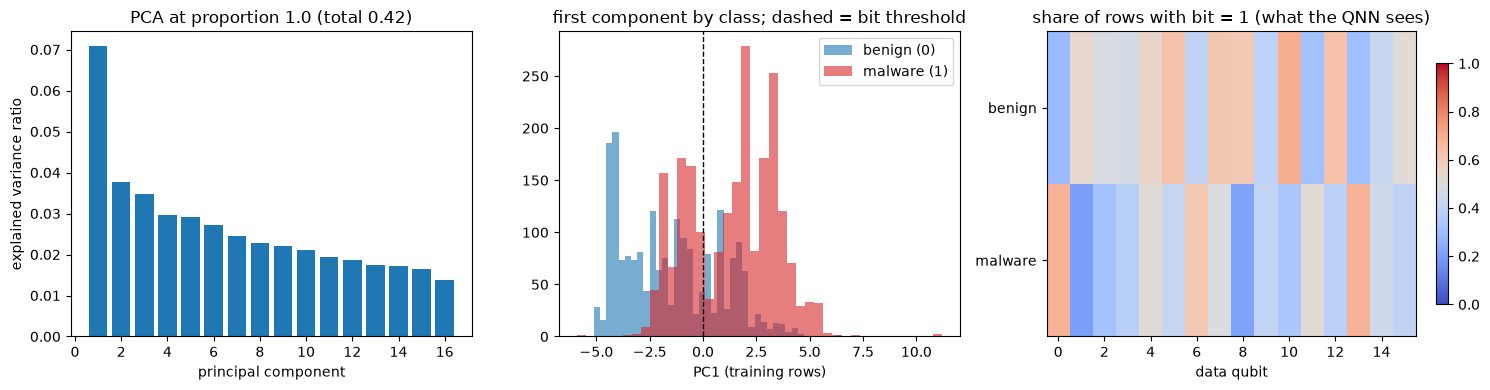

In [5]:
def make_proportion(p, seed):
    '''One of the paper's proportions: stratified subset -> stratified 80/20 split -> one-hot -> standardise -> PCA(16) -> bits.'''
    n = int(round(p * len(df)))
    if n < len(df):
        sub, _ = train_test_split(df, train_size=n, stratify=df["class"], random_state=seed)   # paper: class proportion preserved
    else:
        sub = df
    tr, te = train_test_split(sub, test_size=TEST_SIZE, stratify=sub["class"], random_state=seed)   # CHOICE: 80/20 split
    encode = ColumnTransformer([("packer", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["packer_type"]),
                                ("num", "passthrough", NUMERIC)])
    pipe = Pipeline([("encode", encode),                                   # paper: categorical packer type -> numbers
                     ("scale", StandardScaler()),                          # paper: mean 0, std 1 (fit on train only)
                     ("pca", PCA(n_components=N_QUBITS, random_state=seed))]).fit(tr[FEATURES])   # paper: first 16 components
    Xtr, Xte = pipe.transform(tr[FEATURES]), pipe.transform(te[FEATURES])
    n_encoded = pipe["encode"].transform(tr[FEATURES]).shape[1]
    return dict(p=p, n=n, seed=seed, n_encoded=n_encoded, explained=float(pipe["pca"].explained_variance_ratio_.sum()),
                X_train=Xtr, X_test=Xte, y_train=tr["class"].values.astype(int), y_test=te["class"].values.astype(int),
                bits_train=(Xtr > BIT_THRESHOLD).astype(float), bits_test=(Xte > BIT_THRESHOLD).astype(float),   # CHOICE: threshold
                pca=pipe["pca"])

t0 = time.time()
sections = {p: make_proportion(p, SEED) for p in PROPORTIONS}       # the seed-SEED version of every proportion (used for the figures)
summary = pd.DataFrame([{"proportion": p, "rows": s["n"], "train": len(s["y_train"]), "test": len(s["y_test"]),
                         "malware share (train)": round(s["y_train"].mean(), 3), "encoded columns": s["n_encoded"],
                         "PCA(16) explained variance": round(s["explained"], 3),
                         "mean bit value": round(s["bits_train"].mean(), 3)} for p, s in sections.items()])
print(f"preprocessing of {len(PROPORTIONS)} proportions: {time.time()-t0:.1f} s  (paper: 260, 521, ..., 5210 rows)")
display(summary)

s = sections[max(PROPORTIONS)]
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(range(1, N_QUBITS + 1), s["pca"].explained_variance_ratio_, color="tab:blue")
axes[0].set_xlabel("principal component"); axes[0].set_ylabel("explained variance ratio")
axes[0].set_title(f"PCA at proportion {s['p']} (total {s['explained']:.2f})")
for cls, col, lab in [(0, "tab:blue", "benign (0)"), (1, "tab:red", "malware (1)")]:
    m = s["y_train"] == cls
    axes[1].hist(s["X_train"][m, 0], bins=40, alpha=0.6, color=col, label=lab)
axes[1].axvline(BIT_THRESHOLD, color="k", ls="--", lw=1); axes[1].set_xlabel("PC1 (training rows)"); axes[1].legend()
axes[1].set_title("first component by class; dashed = bit threshold")
bit_rate = np.array([s["bits_train"][s["y_train"] == c].mean(0) for c in (0, 1)])
im = axes[2].imshow(bit_rate, aspect="auto", cmap="coolwarm", vmin=0, vmax=1)
axes[2].set_yticks([0, 1]); axes[2].set_yticklabels(["benign", "malware"]); axes[2].set_xlabel("data qubit")
axes[2].set_title("share of rows with bit = 1 (what the QNN sees)"); fig.colorbar(im, ax=axes[2], fraction=0.03)
plt.tight_layout(); plt.show()

## 3. The paper's QNN: the TensorFlow-Quantum tutorial circuit, rebuilt in PennyLane

The paper's description ("encoding the classical data as quantum circuits", "converted into TensorflowQuantum", "a model
circuit layer ... comprising of a two-layer model with the matched size of the data circuit", "wrapped the model circuit in a
TFQ-Keras model", hinge loss, labels -1 / +1) is, step for step, the TFQ *MNIST classification* tutorial, whose input is also
16 values (a 4 x 4 image). That model is:

1. **Data circuit.** One qubit per input; an X gate on qubit *q* when bit *q* is 1 (Fig. 2 of the paper shows such a circuit).
2. **Readout qubit** prepared in |-> (X then H).
3. **Layer 1:** an XX(theta_q) interaction between every data qubit and the readout. **Layer 2:** a ZZ(phi_q) interaction
   between every data qubit and the readout. That is the "two-layer model circuit"; it has 2 x 16 = 32 trainable angles.
4. H on the readout, then the expectation value of Pauli-Z of the readout is the model output in [-1, 1].

PennyLane's `IsingXX(a)` = exp(-i a/2 X X) and `IsingZZ(a)` = exp(-i a/2 Z Z) are Cirq's `XXPowGate` / `ZZPowGate` with
exponent a / pi, so the two models are the same up to a rescaling of the angles.

**The closed form.** Because every XX term commutes with X on the readout, and X|-> = -|->, the XX layer acting on
|->(readout) (x) |b> turns each exp(-i theta_q/2 X_r X_q) into exp(+i theta_q/2 X_q) on the data qubit alone: after layer 1 the
state is still a *product* state, readout |-> times, per data qubit, cos(theta_q/2)|b_q> + i sin(theta_q/2)|1-b_q>, whose
Z-expectation is (-1)^{b_q} cos(theta_q). The final H followed by a Z measurement is a measurement of X_r right after the ZZ
layer, and conjugating X_r through exp(-i phi_q/2 Z_r Z_q) gives X_r (cos phi_q - i sin phi_q Z_r Z_q). Since <-|X_r Z_r^k|-> is
-1 for even k and 0 for odd k, only even subsets of the ZZ terms survive, and the sum over even subsets of a product is
Re of the full product:

$$\langle Z_{\text{readout}}\rangle \;=\; -\,\mathrm{Re}\prod_{q=1}^{16}\Big(\cos\varphi_q \;-\; i\,\sin\varphi_q\,(-1)^{b_q}\cos\theta_q\Big).$$

The cell below builds the 17-qubit circuit, draws it for one training row, and checks the formula against the simulator for
outputs *and* gradients of the hinge loss. The formula is then an exact, 1000x faster way to evaluate the very same model;
everything the paper trains for 100 epochs is run through it, and Section 6 trains the simulator itself on the small
proportions to show that both paths take identical steps.

device: lightning.qubit | wires: 17 | differentiation: adjoint
QNN: 16 data qubits + 1 readout, 32 trainable angles; first training row bits = [1, 0, 0, 0, 1, 0, 0, 1, 1, 0, 0, 0, 1, 1, 0, 1]


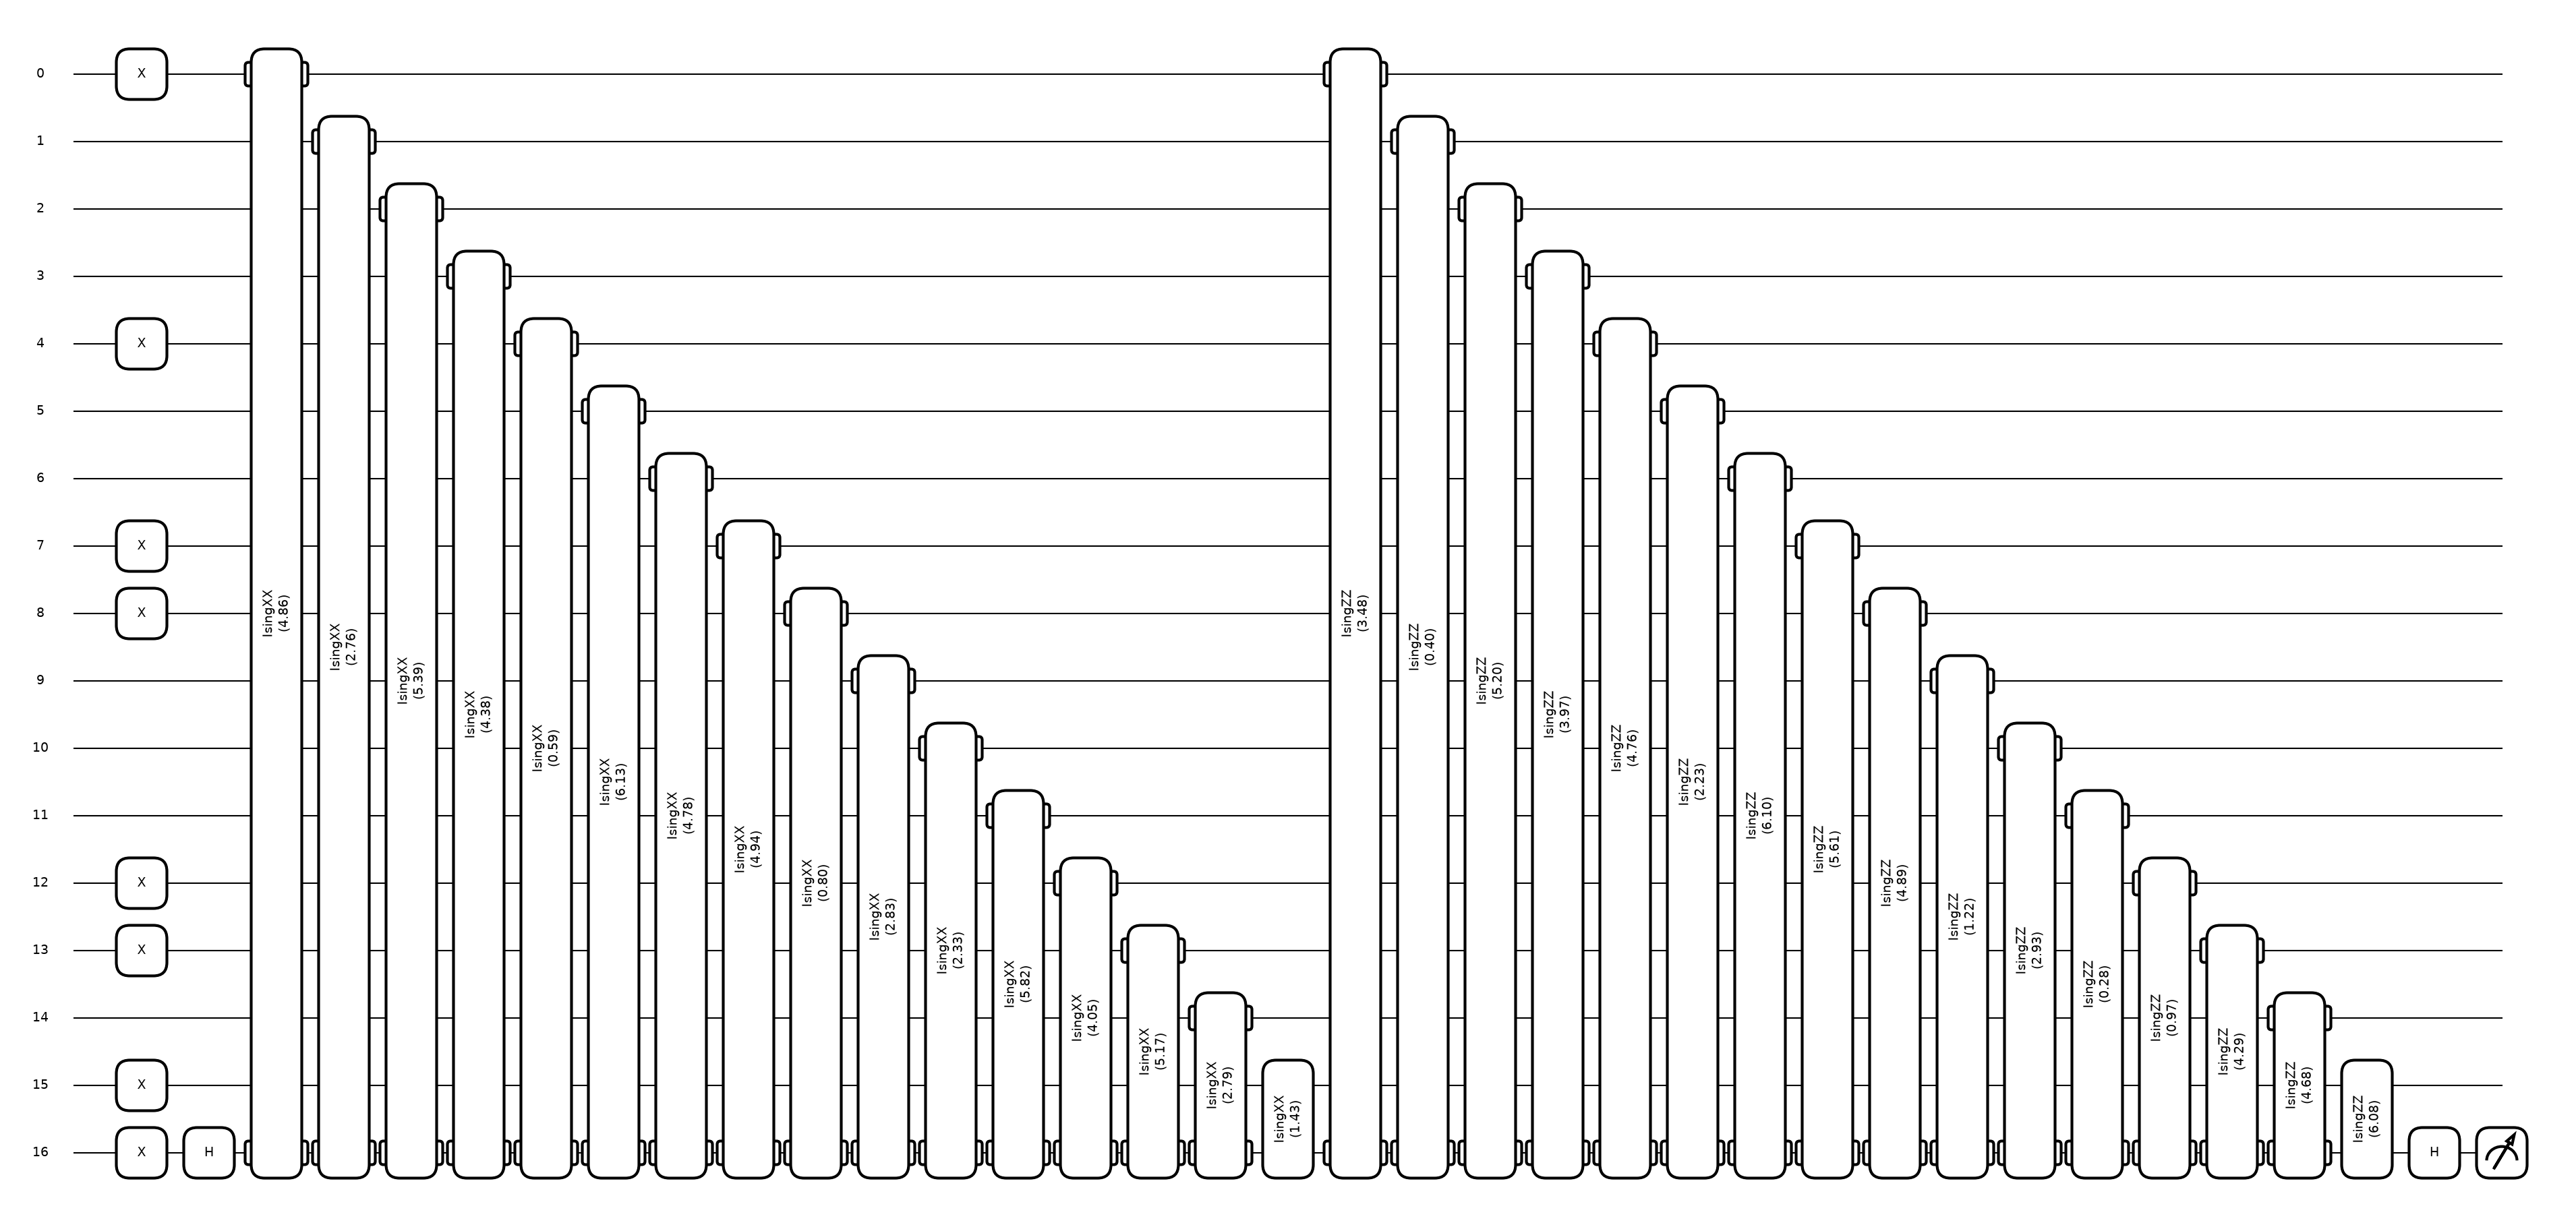

simulator outputs : [ 0.028801 -0.037618 -0.083349  0.052076 -0.020063 -0.076586 -0.02254
  0.049594]
closed form       : [ 0.028801 -0.037618 -0.083349  0.052076 -0.020063 -0.076586 -0.02254
  0.049594]
max |difference|  : outputs 1.0e-15, grad theta 1.1e-16, grad phi 8.2e-16
gradient of the hinge loss, 8 rows: simulator 2.08 s (260 ms/row, forward only 396 ms/row) | closed form 5.1 ms (0.637 ms/row)


In [6]:
READOUT = N_QUBITS                                       # wire index of the readout qubit (data qubits are 0 ... 15)
try:
    dev = qml.device("lightning.qubit", wires=N_QUBITS + 1); DIFF_METHOD = "adjoint"
except Exception as e:                                   # pennylane-lightning missing: fall back to the reference simulator
    print("lightning.qubit unavailable (%s); using default.qubit" % type(e).__name__)
    dev = qml.device("default.qubit", wires=N_QUBITS + 1); DIFF_METHOD = "backprop"
print("device:", dev.name, "| wires:", N_QUBITS + 1, "| differentiation:", DIFF_METHOD)

@qml.qnode(dev, interface="autograd", diff_method=DIFF_METHOD)
def qnn_circuit(bits, theta, phi):
    '''TFQ-tutorial QNN for one row: data circuit (X where bit = 1) + readout in |-> + XX layer + ZZ layer + H + <Z>.'''
    for q in range(N_QUBITS):                            # data circuit (the paper's Fig. 2)
        if bits[q] > 0.5:
            qml.PauliX(wires=q)
    qml.PauliX(wires=READOUT); qml.Hadamard(wires=READOUT)       # readout starts in |->
    for q in range(N_QUBITS):                            # layer 1: XX(theta_q) between data qubit q and the readout
        qml.IsingXX(theta[q], wires=[q, READOUT])
    for q in range(N_QUBITS):                            # layer 2: ZZ(phi_q)
        qml.IsingZZ(phi[q], wires=[q, READOUT])
    qml.Hadamard(wires=READOUT)
    return qml.expval(qml.PauliZ(READOUT))

def qnn_closed_form(bits, theta, phi):
    '''Exact <Z_readout> of qnn_circuit for a batch of bit rows (derivation above); differentiable in theta and phi.'''
    sign = 1.0 - 2.0 * bits                                              # (-1)^bit, shape (batch, 16)
    z = pnp.cos(phi)[None, :] - 1j * pnp.sin(phi)[None, :] * sign * pnp.cos(theta)[None, :]
    return -pnp.real(pnp.prod(z, axis=1))

def hinge_loss(output, y_pm):
    '''TFQ's Hinge loss with labels in {-1, +1}.'''
    return pnp.mean(pnp.maximum(0.0, 1.0 - y_pm * output))

def qnn_cost_cf(theta, phi, bits, y_pm):                 # exact formula
    return hinge_loss(qnn_closed_form(bits, theta, phi), y_pm)

def qnn_cost_sim(theta, phi, bits, y_pm):                # 17-qubit simulation, one circuit per row
    return hinge_loss(pnp.stack([qnn_circuit(bits[i], theta, phi) for i in range(len(y_pm))]), y_pm)

def init_params(seed):
    '''# CHOICE: angles uniform in [0, 2 pi), the default initialiser of TFQ's PQC layer.'''
    r = np.random.default_rng(seed)
    return (pnp.array(r.uniform(0, 2 * np.pi, N_QUBITS), requires_grad=True),
            pnp.array(r.uniform(0, 2 * np.pi, N_QUBITS), requires_grad=True))

# ---- draw the circuit for one training row ----
s = sections[max(PROPORTIONS)]
theta0, phi0 = init_params(SEED)
print(f"QNN: {N_QUBITS} data qubits + 1 readout, {2 * N_QUBITS} trainable angles; first training row bits = "
      f"{s['bits_train'][0].astype(int).tolist()}")
fig, ax = qml.draw_mpl(qnn_circuit, decimals=2)(s["bits_train"][0], theta0, phi0)
plt.show()

# ---- verify the closed form against the simulator: outputs and gradients ----
b8, y8 = s["bits_train"][:8], 2.0 * s["y_train"][:8] - 1.0
t0 = time.perf_counter(); out_sim = np.array([float(qnn_circuit(b8[i], theta0, phi0)) for i in range(8)]); t_fwd = time.perf_counter() - t0
out_cf = np.asarray(qnn_closed_form(b8, theta0, phi0))
t0 = time.perf_counter(); g_sim = qml.grad(qnn_cost_sim, argnums=[0, 1])(theta0, phi0, b8, y8); t_gsim = time.perf_counter() - t0
t0 = time.perf_counter(); g_cf = qml.grad(qnn_cost_cf, argnums=[0, 1])(theta0, phi0, b8, y8); t_gcf = time.perf_counter() - t0
print("simulator outputs :", np.round(out_sim, 6))
print("closed form       :", np.round(out_cf, 6))
print("max |difference|  : outputs %.1e, grad theta %.1e, grad phi %.1e" % (
      np.abs(out_sim - out_cf).max(), np.abs(np.asarray(g_sim[0]) - np.asarray(g_cf[0])).max(),
      np.abs(np.asarray(g_sim[1]) - np.asarray(g_cf[1])).max()))
assert np.allclose(out_sim, out_cf, atol=1e-8) and all(np.allclose(a, b, atol=1e-8) for a, b in zip(g_sim, g_cf))
SIM_MS_PER_SAMPLE, CF_MS_PER_SAMPLE = 1000 * t_gsim / 8, 1000 * t_gcf / 8
print(f"gradient of the hinge loss, 8 rows: simulator {t_gsim:.2f} s ({SIM_MS_PER_SAMPLE:.0f} ms/row, forward only "
      f"{1000 * t_fwd / 8:.0f} ms/row) | closed form {t_gcf * 1000:.1f} ms ({CF_MS_PER_SAMPLE:.3f} ms/row)")

## 4. Training: hinge loss, Adam, 100 epochs; the classical NN and two baselines

**QNN.** The 32 angles are trained with Adam on mini-batches of 32 rows to minimise the hinge loss, the labels being
+1 for malware and -1 for benign, for the paper's 100 epochs; the prediction is malware when the readout expectation is
positive (TFQ's `hinge_accuracy`). `train_qnn` takes the cost function as an argument, so the same loop trains through the
exact formula (`qnn_cost_cf`) or through the 17-qubit simulator (`qnn_cost_sim`); the full-training-set loss after every
epoch is always evaluated with the exact formula because it is free.

**NN.** The paper gives no architecture for its Keras network. We use a 16-16-1 multilayer perceptron (ReLU hidden layer,
sigmoid output, log-loss, Adam, batch 32, 100 epochs: scikit-learn's `MLPClassifier`), applied "directly to the reduced
dataset" of 16 components as the paper says.

**Baselines (not in the paper).** A random forest (200 trees) and an RBF support-vector machine are trained on exactly the
same 16 components, and all three classical models are also trained on the 16 *bits* the QNN sees, which isolates the cost
of the binary encoding from the capacity of the circuit.

All metrics use malware (class 1) as the positive class. "Execution time" is the wall-clock time of training plus
prediction, which is what the paper's tables most plausibly report.

In [7]:
def train_qnn(bits, y, seed, epochs, cost=qnn_cost_cf):
    '''Adam on mini-batches of the hinge loss; returns (theta, phi, full-training-set loss per epoch).'''
    theta, phi = init_params(seed)
    r = np.random.default_rng(seed + 1000)                            # batch order
    opt = qml.AdamOptimizer(stepsize=LR)
    bits = np.asarray(bits, dtype=float); y_pm = 2.0 * np.asarray(y, dtype=float) - 1.0   # paper: labels -> -1 / +1
    losses = []
    for ep in range(epochs):
        perm = r.permutation(len(y_pm))
        for i in range(0, len(y_pm), BATCH_SIZE):
            b = perm[i:i + BATCH_SIZE]
            theta, phi, _, _ = opt.step(cost, theta, phi, bits[b], y_pm[b])
        losses.append(float(qnn_cost_cf(theta, phi, bits, y_pm)))
    return theta, phi, losses

def qnn_predict_cf(theta, phi, bits):
    return (np.asarray(qnn_closed_form(np.asarray(bits, dtype=float), theta, phi)) > 0).astype(int)

def qnn_predict_sim(theta, phi, bits):
    return (np.array([float(qnn_circuit(np.asarray(b, dtype=float), theta, phi)) for b in bits]) > 0).astype(int)

def classical_models(seed):
    return {"NN (MLP 16-16-1)": MLPClassifier(hidden_layer_sizes=(HIDDEN,), max_iter=EPOCHS, batch_size=BATCH_SIZE,
                                              random_state=seed),                      # CHOICE: stands in for the paper's Keras NN
            "RandomForest":     RandomForestClassifier(n_estimators=200, random_state=seed),
            "SVC (rbf)":        SVC(kernel="rbf", C=1.0, random_state=seed)}

def metrics(y_true, y_pred):
    '''The paper's four metrics with malware (class 1) as the positive class.'''
    return dict(accuracy=accuracy_score(y_true, y_pred),
                precision=precision_score(y_true, y_pred, pos_label=1, zero_division=0),
                recall=recall_score(y_true, y_pred, pos_label=1, zero_division=0),
                f1=f1_score(y_true, y_pred, pos_label=1, zero_division=0))

# smoke test on the smallest proportion: 2 epochs through the exact formula
s = sections[min(PROPORTIONS)]
t0 = time.perf_counter(); th, ph, L = train_qnn(s["bits_train"], s["y_train"], SEED, 2); t = time.perf_counter() - t0
print(f"smoke test, proportion {s['p']}: 2 epochs in {t:.2f} s, loss {L[0]:.3f} -> {L[1]:.3f}, "
      f"test accuracy {accuracy_score(s['y_test'], qnn_predict_cf(th, ph, s['bits_test'])):.3f}")

smoke test, proportion 0.05: 2 epochs in 0.11 s, loss 0.995 -> 0.991, test accuracy 0.538


## 5. Running the paper's protocol: 20 proportions, QNN and NN, several seeds

For every proportion and every seed the cell below draws the subset, splits it, fits the preprocessing on the training
split, trains the QNN (exact formula, 100 epochs), the NN and the two baselines on the 16 components, and the three classical
models on the 16 bits, and records the four metrics and the execution time. The seed changes the subset, the split, the PCA,
the parameter initialisation and the batch order, so the spread over seeds is the spread a reader of the paper should expect
between two runs of the same experiment. The tables printed afterwards are this notebook's Table 1 (QNN) and Table 2 (NN)
for the main seed, followed by mean +- std over seeds.

In [8]:
rows, loss_curves, trained = [], {}, {}
t_all = time.time()
for p in PROPORTIONS:
    t_p = time.time()
    for seed in SEEDS:
        s = sections[p] if seed == SEED else make_proportion(p, seed)
        # --- QNN through the exact formula, 100 epochs ---
        t0 = time.perf_counter(); theta, phi, losses = train_qnn(s["bits_train"], s["y_train"], seed, EPOCHS); t_fit = time.perf_counter() - t0
        t0 = time.perf_counter(); pred = qnn_predict_cf(theta, phi, s["bits_test"]); t_pred = time.perf_counter() - t0
        rows.append(dict(proportion=p, rows=s["n"], seed=seed, model="QNN", inputs="16 bits", fit_s=t_fit, predict_s=t_pred,
                         train_accuracy=accuracy_score(s["y_train"], qnn_predict_cf(theta, phi, s["bits_train"])),
                         **metrics(s["y_test"], pred)))
        if seed == SEED:
            loss_curves[p] = losses; trained[p] = dict(theta=theta, phi=phi, y_pred=pred)
        # --- classical models on the 16 components (the paper's NN input) and on the 16 bits (the QNN's input) ---
        for inputs, Xtr, Xte in [("16 PCs", s["X_train"], s["X_test"]), ("16 bits", s["bits_train"], s["bits_test"])]:
            for name, model in classical_models(seed).items():
                t0 = time.perf_counter(); model.fit(Xtr, s["y_train"]); t_fit = time.perf_counter() - t0
                t0 = time.perf_counter(); pred = model.predict(Xte); t_pred = time.perf_counter() - t0
                rows.append(dict(proportion=p, rows=s["n"], seed=seed, model=name, inputs=inputs, fit_s=t_fit, predict_s=t_pred,
                                 train_accuracy=accuracy_score(s["y_train"], model.predict(Xtr)), **metrics(s["y_test"], pred)))
                if seed == SEED and name.startswith("NN") and inputs == "16 PCs":
                    trained[p]["nn_pred"] = pred
    q = [r for r in rows if r["proportion"] == p and r["model"] == "QNN"]
    n = [r for r in rows if r["proportion"] == p and r["model"].startswith("NN") and r["inputs"] == "16 PCs"]
    print(f"proportion {p:4.2f} ({s['n']:4d} rows): QNN accuracy {np.mean([r['accuracy'] for r in q]):.3f}, "
          f"NN accuracy {np.mean([r['accuracy'] for r in n]):.3f} over {len(SEEDS)} seeds | {time.time() - t_p:5.1f} s", flush=True)
results = pd.DataFrame(rows)
results["time_s"] = results["fit_s"] + results["predict_s"]
print(f"total: {(time.time() - t_all) / 60:.1f} min for {len(PROPORTIONS)} proportions x {len(SEEDS)} seeds")

def paper_table(model, inputs, seed=SEED):
    t = results[(results.model == model) & (results.inputs == inputs) & (results.seed == seed)]
    t = t[["proportion", "rows", "precision", "recall", "f1", "accuracy", "time_s"]].rename(columns={"time_s": "execution time (s)"})
    return t.set_index("proportion").round(3)

print("\nThis notebook's Table 1: QNN (exact formula, 100 epochs), main seed")
display(paper_table("QNN", "16 bits"))
print("This notebook's Table 2: NN (MLP 16-16-1, 100 epochs) on the 16 components, main seed")
display(paper_table("NN (MLP 16-16-1)", "16 PCs"))

def mean_std_table(metric):
    g = results.groupby(["proportion", "model", "inputs"])[metric].agg(["mean", "std"])
    txt = g.apply(lambda r: f"{r['mean']:.3f} +- {r['std']:.3f}", axis=1).unstack(["model", "inputs"])
    cols = [("QNN", "16 bits"), ("NN (MLP 16-16-1)", "16 PCs"), ("RandomForest", "16 PCs"), ("SVC (rbf)", "16 PCs"),
            ("NN (MLP 16-16-1)", "16 bits"), ("RandomForest", "16 bits"), ("SVC (rbf)", "16 bits")]
    return txt[cols]
for metric in ["accuracy", "f1"]:
    print(f"\n{metric}: mean +- std over {len(SEEDS)} seeds (columns: model, inputs)")
    display(mean_std_table(metric))

proportion 0.05 ( 260 rows): QNN accuracy 0.731, NN accuracy 0.923 over 3 seeds |  32.1 s


proportion 0.10 ( 521 rows): QNN accuracy 0.673, NN accuracy 0.943 over 3 seeds |  31.4 s


proportion 0.15 ( 782 rows): QNN accuracy 0.715, NN accuracy 0.926 over 3 seeds |  51.6 s


proportion 0.20 (1042 rows): QNN accuracy 0.788, NN accuracy 0.954 over 3 seeds |  64.8 s


proportion 0.25 (1302 rows): QNN accuracy 0.719, NN accuracy 0.937 over 3 seeds |  81.6 s


...

,rows,precision,recall,f1,accuracy,execution time (s)
proportion,,,,,,
0.05,260,0.788,0.963,0.867,0.846,0.887
0.10,521,0.945,0.945,0.945,0.943,2.055
0.15,782,0.941,0.976,0.958,0.955,2.609
0.20,1042,0.946,0.963,0.955,0.952,2.191
0.25,1302,0.956,0.949,0.952,0.950,2.493
0.30,1563,0.969,0.957,0.963,0.962,3.933
0.35,1823,0.959,0.969,0.964,0.962,3.200
0.40,2084,0.954,0.959,0.957,0.954,4.154
0.45,2344,0.983,0.963,0.973,0.972,7.307



accuracy: mean +- std over 3 seeds (columns: model, inputs)


model,QNN,NN (MLP 16-16-1),RandomForest,SVC (rbf),NN (MLP 16-16-1),RandomForest,SVC (rbf)
inputs,16 bits,16 PCs,16 PCs,16 PCs,16 bits,16 bits,16 bits
proportion,,,,,,,
0.05,0.731 +- 0.033,0.923 +- 0.069,0.929 +- 0.044,0.917 +- 0.059,0.917 +- 0.080,0.929 +- 0.029,0.936 +- 0.048
0.10,0.673 +- 0.124,0.943 +- 0.010,0.927 +- 0.011,0.917 +- 0.015,0.908 +- 0.045,0.902 +- 0.045,0.921 +- 0.038
0.15,0.715 +- 0.091,0.926 +- 0.027,0.934 +- 0.027,0.921 +- 0.024,0.909 +- 0.015,0.926 +- 0.013,0.911 +- 0.025
0.20,0.788 +- 0.048,0.954 +- 0.007,0.955 +- 0.012,0.939 +- 0.003,0.911 +- 0.010,0.938 +- 0.008,0.928 +- 0.008
0.25,0.719 +- 0.061,0.937 +- 0.013,0.949 +- 0.015,0.925 +- 0.033,0.908 +- 0.021,0.930 +- 0.013,0.920 +- 0.014
0.30,0.740 +- 0.086,0.961 +- 0.008,0.969 +- 0.012,0.956 +- 0.010,0.937 +- 0.013,0.953 +- 0.004,0.951 +- 0.005
0.35,0.795 +- 0.026,0.956 +- 0.007,0.959 +- 0.005,0.953 +- 0.007,0.943 +- 0.018,0.944 +- 0.019,0.946 +- 0.015
0.40,0.787 +- 0.019,0.953 +- 0.014,0.954 +- 0.016,0.941 +- 0.011,0.922 +- 0.016,0.932 +- 0.006,0.929 +- 0.012



f1: mean +- std over 3 seeds (columns: model, inputs)


model,QNN,NN (MLP 16-16-1),RandomForest,SVC (rbf),NN (MLP 16-16-1),RandomForest,SVC (rbf)
inputs,16 bits,16 PCs,16 PCs,16 PCs,16 bits,16 bits,16 bits
proportion,,,,,,,
0.05,0.734 +- 0.030,0.931 +- 0.059,0.934 +- 0.041,0.925 +- 0.051,0.922 +- 0.076,0.934 +- 0.027,0.941 +- 0.045
0.10,0.685 +- 0.123,0.947 +- 0.008,0.932 +- 0.009,0.923 +- 0.013,0.914 +- 0.038,0.908 +- 0.041,0.926 +- 0.035
0.15,0.723 +- 0.094,0.930 +- 0.025,0.938 +- 0.024,0.928 +- 0.021,0.915 +- 0.012,0.931 +- 0.011,0.919 +- 0.022
0.20,0.787 +- 0.068,0.957 +- 0.007,0.958 +- 0.012,0.944 +- 0.003,0.914 +- 0.007,0.941 +- 0.008,0.932 +- 0.008
0.25,0.739 +- 0.039,0.940 +- 0.012,0.952 +- 0.014,0.930 +- 0.029,0.914 +- 0.020,0.933 +- 0.011,0.925 +- 0.012
0.30,0.758 +- 0.085,0.963 +- 0.008,0.971 +- 0.011,0.959 +- 0.009,0.940 +- 0.013,0.956 +- 0.003,0.954 +- 0.006
0.35,0.813 +- 0.023,0.959 +- 0.006,0.961 +- 0.005,0.957 +- 0.007,0.947 +- 0.016,0.947 +- 0.018,0.949 +- 0.013
0.40,0.801 +- 0.011,0.955 +- 0.014,0.956 +- 0.016,0.945 +- 0.010,0.926 +- 0.016,0.935 +- 0.006,0.933 +- 0.012


## 6. The 17-qubit simulation itself: identical steps, measured cost

The formula is only a faster way to evaluate the circuit; the paper trained its QNN through a simulator and reports how long
that took. Here the same training loop is run through PennyLane's state-vector simulator (`lightning.qubit`, adjoint
differentiation, one 17-qubit circuit per row and step) on the smaller proportions for a few epochs, with the same seed and
batch order as the formula. Three things are checked and recorded:

* the parameters after `SIM_EPOCHS` epochs agree with the formula's parameters after the same epochs (max difference ~1e-8),
* the test predictions of the simulator-trained model are identical to the formula-trained model's at that point,
* the wall-clock cost per epoch, which is what a reader needs to judge the paper's "execution time" claims.

In [9]:
sim_rows, sim_curves = [], {}
for p in SIM_PROPORTIONS:
    s = sections[p]
    theta_cf, phi_cf, _ = train_qnn(s["bits_train"], s["y_train"], SEED, SIM_EPOCHS)                       # reference: formula
    t0 = time.perf_counter(); theta_sim, phi_sim, losses_sim = train_qnn(s["bits_train"], s["y_train"], SEED, SIM_EPOCHS, cost=qnn_cost_sim)
    t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); pred_sim = qnn_predict_sim(theta_sim, phi_sim, s["bits_test"]); t_pred = time.perf_counter() - t0
    pred_cf = qnn_predict_cf(theta_cf, phi_cf, s["bits_test"])
    max_diff = max(np.abs(np.asarray(theta_sim) - np.asarray(theta_cf)).max(), np.abs(np.asarray(phi_sim) - np.asarray(phi_cf)).max())
    sim_curves[p] = losses_sim
    sim_rows.append(dict(proportion=p, train_rows=len(s["y_train"]), test_rows=len(s["y_test"]), epochs=SIM_EPOCHS,
                         fit_s=t_fit, predict_s=t_pred, s_per_epoch=t_fit / SIM_EPOCHS,
                         ms_per_training_row=1000 * t_fit / (SIM_EPOCHS * len(s["y_train"])),
                         max_param_diff_vs_formula=max_diff, identical_predictions=bool(np.array_equal(pred_sim, pred_cf)),
                         **metrics(s["y_test"], pred_sim)))
    print(f"proportion {p}: simulator {SIM_EPOCHS} epochs on {len(s['y_train'])} rows in {t_fit:.0f} s, prediction {t_pred:.1f} s, "
          f"max parameter difference vs formula {max_diff:.1e}, predictions identical: {sim_rows[-1]['identical_predictions']}, "
          f"test accuracy {sim_rows[-1]['accuracy']:.3f}", flush=True)
    assert max_diff < 1e-5, "simulator and closed form diverged"
sim_results = pd.DataFrame(sim_rows).set_index("proportion")
display(sim_results.round(4))
full_epoch_s = sim_results["ms_per_training_row"].mean() / 1000 * len(sections[max(PROPORTIONS)]["y_train"])
print(f"at this speed one epoch of the simulator on the 100 % proportion ({len(sections[max(PROPORTIONS)]['y_train'])} rows) "
      f"would take about {full_epoch_s / 60:.0f} min, i.e. {EPOCHS * full_epoch_s / 3600:.0f} h for the paper's 100 epochs; "
      f"the exact formula does the same in {results[(results.model == 'QNN') & (results.proportion == max(PROPORTIONS))]['fit_s'].mean():.0f} s.")

proportion 0.05: simulator 2 epochs on 208 rows in 39 s, prediction 5.4 s, max parameter difference vs formula 1.8e-15, predictions identical: True, test accuracy 0.538


proportion 0.1: simulator 2 epochs on 416 rows in 88 s, prediction 10.6 s, max parameter difference vs formula 4.0e-15, predictions identical: True, test accuracy 0.581


proportion 0.25: simulator 2 epochs on 1041 rows in 163 s, prediction 18.2 s, max parameter difference vs formula 3.6e-15, predictions identical: True, test accuracy 0.559


,train_rows,test_rows,epochs,fit_s,predict_s,s_per_epoch,ms_per_training_row,max_param_diff_vs_formula,identical_predictions,accuracy,precision,recall,f1
proportion,,,,,,,,,,,,,
0.05,208,52,2,38.8752,5.4105,19.4376,93.4500,0.0,True,0.5385,0.5429,0.7037,0.6129
0.10,416,105,2,88.4876,10.5633,44.2438,106.3553,0.0,True,0.5810,0.5965,0.6182,0.6071
0.25,1041,261,2,162.9743,18.2046,81.4872,78.2778,0.0,True,0.5594,0.5686,0.6397,0.6021


at this speed one epoch of the simulator on the 100 % proportion (4168 rows) would take about 6 min, i.e. 11 h for the paper's 100 epochs; the exact formula does the same in 34 s.


## 7. Figures: the paper's tables as curves, loss curves, execution time, confusion matrices

The first figure overlays this notebook's accuracy and F1 per proportion (mean +- std over seeds) on the paper's Table 1 (QNN)
and Table 2 (NN) values. The second shows the QNN's training loss per epoch for a few proportions, plus the simulator's loss
for the epochs it ran (it must lie exactly on the formula's curve). The third compares execution times: the paper's (about
10 minutes per proportion for the QNN, 15-85 s for the NN) against ours (formula, simulator, MLP). The confusion matrices are
for the smallest and the largest proportion, malware being the positive class.

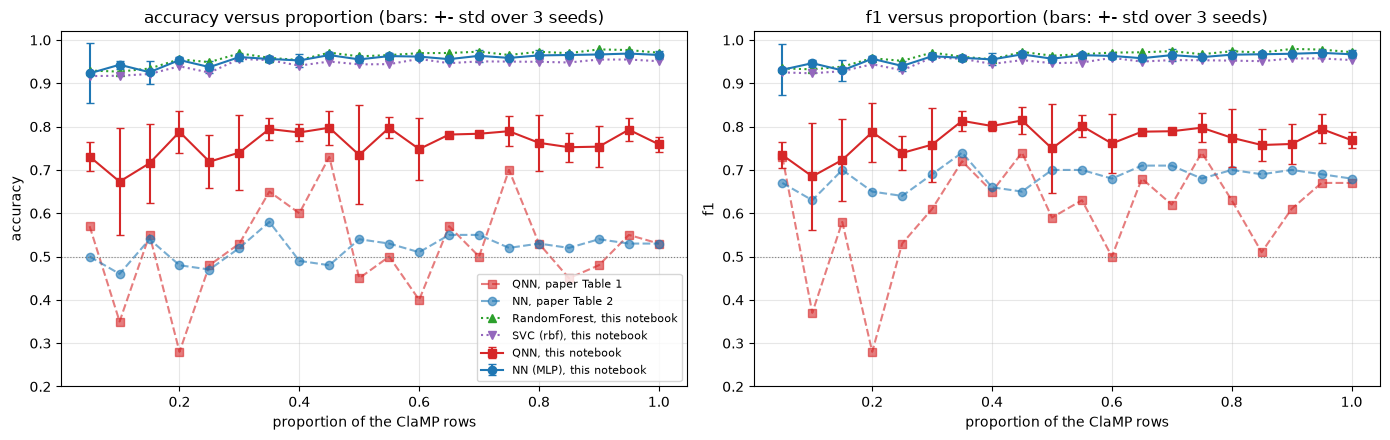

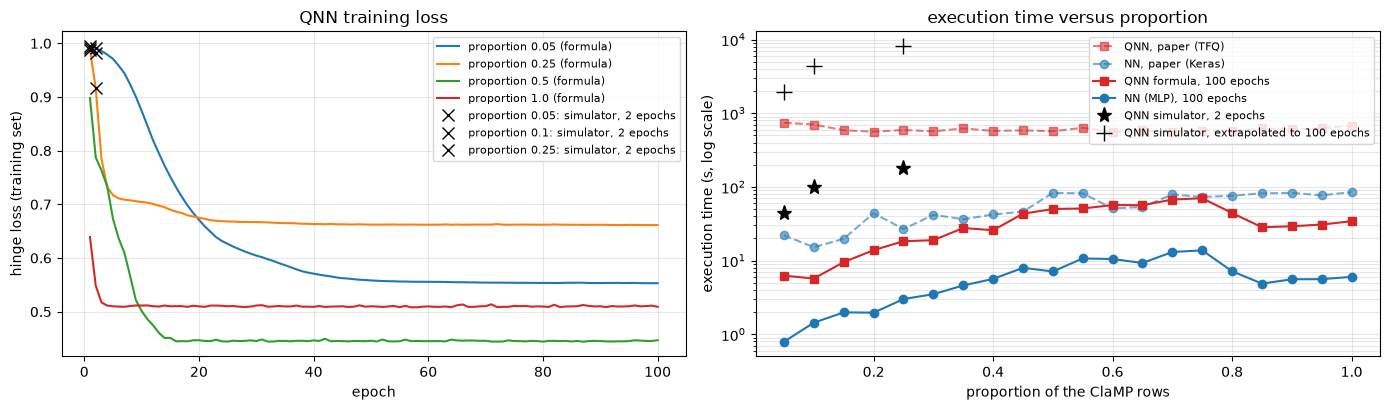

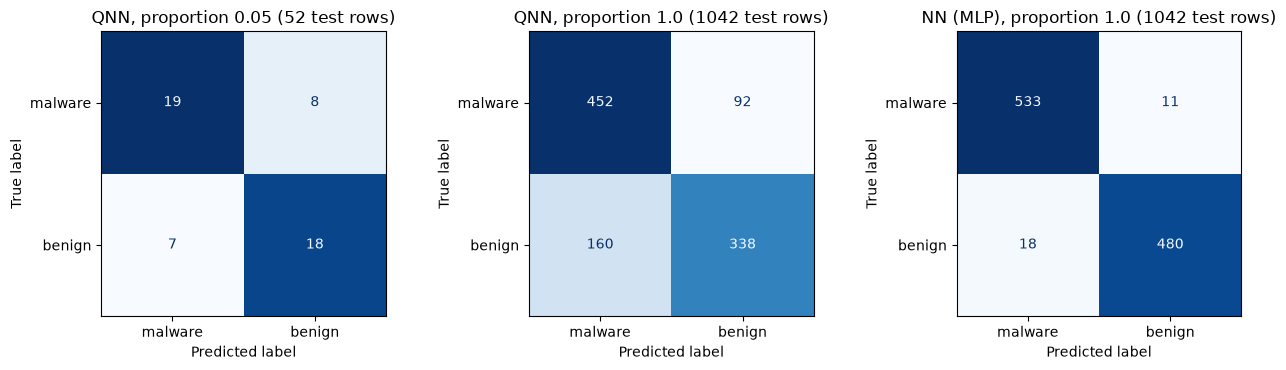

QNN at proportion 1.0:
              precision    recall  f1-score   support

 malware (1)      0.739     0.831     0.782       544
  benign (0)      0.786     0.679     0.728       498

    accuracy                          0.758      1042
   macro avg      0.762     0.755     0.755      1042
weighted avg      0.761     0.758     0.756      1042



In [10]:
PAPER_QNN = {0.05: (1.00, 0.57, 0.73, 0.57, 744), 0.10: (0.42, 0.35, 0.37, 0.35, 702), 0.15: (0.68, 0.55, 0.58, 0.55, 588),
             0.20: (0.30, 0.28, 0.28, 0.28, 562), 0.25: (0.64, 0.47, 0.53, 0.48, 593), 0.30: (0.87, 0.53, 0.61, 0.53, 568),
             0.35: (0.92, 0.65, 0.72, 0.65, 623), 0.40: (0.89, 0.60, 0.65, 0.60, 576), 0.45: (0.83, 0.72, 0.74, 0.73, 585),
             0.50: (0.86, 0.45, 0.59, 0.45, 570), 0.55: (0.86, 0.50, 0.63, 0.50, 635), 0.60: (0.67, 0.40, 0.50, 0.40, 560),
             0.65: (0.82, 0.57, 0.68, 0.57, 585), 0.70: (0.80, 0.50, 0.62, 0.50, 559), 0.75: (0.90, 0.70, 0.74, 0.70, 582),
             0.80: (0.85, 0.53, 0.63, 0.53, 580), 0.85: (0.82, 0.45, 0.51, 0.45, 621), 0.90: (0.86, 0.47, 0.61, 0.48, 607),
             0.95: (0.87, 0.55, 0.67, 0.55, 624), 1.00: (0.93, 0.53, 0.67, 0.53, 681)}      # Table 1: precision, recall, F1, accuracy, seconds
PAPER_NN  = {0.05: (1.00, 0.50, 0.67, 0.50, 22.1), 0.10: (1.00, 0.46, 0.63, 0.46, 15.2), 0.15: (1.00, 0.54, 0.70, 0.54, 19.8),
             0.20: (1.00, 0.48, 0.65, 0.48, 44.0), 0.25: (1.00, 0.47, 0.64, 0.47, 26.8), 0.30: (1.00, 0.52, 0.69, 0.52, 41.9),
             0.35: (1.00, 0.58, 0.74, 0.58, 36.4), 0.40: (1.00, 0.49, 0.66, 0.49, 42.3), 0.45: (1.00, 0.48, 0.65, 0.48, 46.3),
             0.50: (1.00, 0.54, 0.70, 0.54, 83.0), 0.55: (1.00, 0.53, 0.70, 0.53, 82.0), 0.60: (1.00, 0.51, 0.68, 0.51, 51.1),
             0.65: (1.00, 0.55, 0.71, 0.55, 53.6), 0.70: (1.00, 0.55, 0.71, 0.55, 79.0), 0.75: (1.00, 0.52, 0.68, 0.52, 73.0),
             0.80: (1.00, 0.53, 0.70, 0.53, 76.0), 0.85: (1.00, 0.52, 0.69, 0.52, 82.0), 0.90: (1.00, 0.54, 0.70, 0.54, 83.0),
             0.95: (1.00, 0.53, 0.69, 0.53, 77.0), 1.00: (1.00, 0.52, 0.68, 0.53, 85.0)}      # Table 2
paper_q = pd.DataFrame(PAPER_QNN, index=["precision", "recall", "f1", "accuracy", "time_s"]).T
paper_n = pd.DataFrame(PAPER_NN,  index=["precision", "recall", "f1", "accuracy", "time_s"]).T

def ours(model, inputs):
    t = results[(results.model == model) & (results.inputs == inputs)]
    return t.groupby("proportion")[["accuracy", "f1", "time_s"]].agg(["mean", "std"])
our_q, our_n = ours("QNN", "16 bits"), ours("NN (MLP 16-16-1)", "16 PCs")
our_rf, our_sv = ours("RandomForest", "16 PCs"), ours("SVC (rbf)", "16 PCs")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, metric in zip(axes, ["accuracy", "f1"]):
    ax.plot(paper_q.index, paper_q[metric], "s--", color="tab:red", alpha=0.6, label="QNN, paper Table 1")
    ax.plot(paper_n.index, paper_n[metric], "o--", color="tab:blue", alpha=0.6, label="NN, paper Table 2")
    ax.errorbar(our_q.index, our_q[(metric, "mean")], yerr=our_q[(metric, "std")], fmt="s-", color="tab:red", capsize=3, label="QNN, this notebook")
    ax.errorbar(our_n.index, our_n[(metric, "mean")], yerr=our_n[(metric, "std")], fmt="o-", color="tab:blue", capsize=3, label="NN (MLP), this notebook")
    ax.plot(our_rf.index, our_rf[(metric, "mean")], "^:", color="tab:green", label="RandomForest, this notebook")
    ax.plot(our_sv.index, our_sv[(metric, "mean")], "v:", color="tab:purple", label="SVC (rbf), this notebook")
    ax.axhline(0.5, color="gray", lw=0.8, ls=":"); ax.set_xlabel("proportion of the ClaMP rows"); ax.set_ylabel(metric)
    ax.set_ylim(0.2, 1.02); ax.grid(alpha=0.3); ax.set_title(f"{metric} versus proportion (bars: +- std over {len(SEEDS)} seeds)")
axes[0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
show = [p for p in PROPORTIONS if p in (min(PROPORTIONS), 0.25, 0.5, max(PROPORTIONS))] or PROPORTIONS[:4]
for p in show:
    axes[0].plot(range(1, EPOCHS + 1), loss_curves[p], label=f"proportion {p} (formula)")
for p, L in sim_curves.items():
    axes[0].plot(range(1, len(L) + 1), L, "kx", ms=8, label=f"proportion {p}: simulator, {len(L)} epochs")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("hinge loss (training set)"); axes[0].set_title("QNN training loss"); axes[0].legend(fontsize=8); axes[0].grid(alpha=0.3)
axes[1].plot(paper_q.index, paper_q["time_s"], "s--", color="tab:red", alpha=0.6, label="QNN, paper (TFQ)")
axes[1].plot(paper_n.index, paper_n["time_s"], "o--", color="tab:blue", alpha=0.6, label="NN, paper (Keras)")
axes[1].plot(our_q.index, our_q[("time_s", "mean")], "s-", color="tab:red", label=f"QNN formula, {EPOCHS} epochs")
axes[1].plot(our_n.index, our_n[("time_s", "mean")], "o-", color="tab:blue", label=f"NN (MLP), {EPOCHS} epochs")
axes[1].plot(sim_results.index, sim_results["fit_s"] + sim_results["predict_s"], "k*", ms=11, label=f"QNN simulator, {SIM_EPOCHS} epochs")
axes[1].plot(sim_results.index, (sim_results["s_per_epoch"] * EPOCHS), "k+", ms=11, label=f"QNN simulator, extrapolated to {EPOCHS} epochs")
axes[1].set_yscale("log"); axes[1].set_xlabel("proportion of the ClaMP rows"); axes[1].set_ylabel("execution time (s, log scale)")
axes[1].set_title("execution time versus proportion"); axes[1].legend(fontsize=8); axes[1].grid(alpha=0.3, which="both")
plt.tight_layout(); plt.show()

pairs = [(min(PROPORTIONS), "y_pred", "QNN"), (max(PROPORTIONS), "y_pred", "QNN"), (max(PROPORTIONS), "nn_pred", "NN (MLP)")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (p, key, name) in zip(axes, pairs):
    cm = confusion_matrix(sections[p]["y_test"], trained[p][key], labels=[1, 0])
    ConfusionMatrixDisplay(cm, display_labels=["malware", "benign"]).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{name}, proportion {p} ({len(sections[p]['y_test'])} test rows)")
plt.tight_layout(); plt.show()
p = max(PROPORTIONS)
print(f"QNN at proportion {p}:\n" + classification_report(sections[p]["y_test"], trained[p]["y_pred"], labels=[1, 0],
                                                            target_names=["malware (1)", "benign (0)"], digits=3))

## 8. Paper versus this notebook

Each row is one number from the paper's Table 1 or Table 2 for a proportion this notebook ran. The verdict is **reproduced**
when our value (main seed) is within 2 accuracy points / 0.02 F1 of the paper's, **exceeded** when it is higher by more, **not
reached** when it is lower by more; execution times are on different hardware and software and **cannot be checked**, so the
qualitative time claims are judged on the shape of our curves instead. In `FAST_MODE` only five proportions are compared.

In [11]:
TOL = 0.02
def verdict(paper, ours_, tol=TOL):
    if abs(ours_ - paper) <= tol: return "reproduced"
    return f"exceeded (+{ours_ - paper:.2f})" if ours_ > paper else f"not reached ({ours_ - paper:.2f})"

main_q = paper_table("QNN", "16 bits"); main_n = paper_table("NN (MLP 16-16-1)", "16 PCs")
comp = []
for p in PROPORTIONS:
    for model, paper_t, our_t in [("QNN", paper_q, main_q), ("NN", paper_n, main_n)]:
        for metric in ["accuracy", "f1", "precision", "recall"]:
            comp.append(dict(proportion=p, model=model, metric=metric, paper=paper_t.loc[p, metric],
                             notebook=round(float(our_t.loc[p, metric]), 3), verdict=verdict(paper_t.loc[p, metric], float(our_t.loc[p, metric]))))
        comp.append(dict(proportion=p, model=model, metric="execution time (s)", paper=paper_t.loc[p, "time_s"],
                         notebook=round(float(our_t.loc[p, "execution time (s)"]), 1), verdict="cannot be checked (other hardware/software)"))
comparison = pd.DataFrame(comp)
print("Accuracy and F1 rows:")
display(comparison[comparison.metric.isin(["accuracy", "f1"])].set_index(["proportion", "model", "metric"]))
counts_v = comparison[comparison.metric.isin(["accuracy", "f1", "precision", "recall"])].verdict.str.split(" (", regex=False).str[0].value_counts()
print("verdict counts over accuracy / F1 / precision / recall rows:", counts_v.to_dict())

# --- the paper's qualitative claims ---
qa = results[(results.model == "QNN")].groupby("proportion")["accuracy"].mean()
na = results[(results.model == "NN (MLP 16-16-1)") & (results.inputs == "16 PCs")].groupby("proportion")["accuracy"].mean()
qt = results[(results.model == "QNN")].groupby("proportion")["time_s"].mean()
nt = results[(results.model == "NN (MLP 16-16-1)") & (results.inputs == "16 PCs")].groupby("proportion")["time_s"].mean()
rho_q, rho_n = spearmanr(qa.index, qa.values)[0], spearmanr(na.index, na.values)[0]
rho_qt, rho_nt = spearmanr(qt.index, qt.values)[0], spearmanr(nt.index, nt.values)[0]
sim_t = (sim_results["s_per_epoch"] * EPOCHS)
claims = pd.DataFrame([
    dict(claim="QNN accuracy is 'random' across proportions (0.28-0.73 in the paper)",
         notebook=f"QNN accuracy {qa.min():.2f}-{qa.max():.2f}, Spearman rho(proportion, accuracy) = {rho_q:+.2f}; spread over seeds "
                  f"+-{results[results.model == 'QNN'].groupby('proportion')['accuracy'].std().mean():.2f}",
         verdict="not reproduced: no chance-level scores; mild size dependence within seed noise" if qa.min() > 0.6 else "partly reproduced"),
    dict(claim="NN accuracy is 'random' and near 0.5 at every proportion",
         notebook=f"NN accuracy {na.min():.2f}-{na.max():.2f}, rho = {rho_n:+.2f}",
         verdict="not reproduced: the NN is far above chance and improves with data" if na.min() > 0.7 else "partly reproduced"),
    dict(claim="QNN execution time decreases with more data (15 % to 80 %)",
         notebook=f"formula time rho = {rho_qt:+.2f}; simulator {sim_results['ms_per_training_row'].mean():.0f} ms per row and epoch, "
                  f"i.e. linear in the number of rows",
         verdict="not reproduced: time grows with the proportion"),
    dict(claim="NN execution time increases with more data",
         notebook=f"MLP time {nt.min():.1f}-{nt.max():.1f} s, rho = {rho_nt:+.2f}",
         verdict="reproduced" if rho_nt > 0.5 else "not reproduced"),
    dict(claim="QNN is much slower than NN (about 10 min vs about 1 min)",
         notebook=f"simulated QNN extrapolated to {EPOCHS} epochs: {sim_t.min() / 60:.0f}-{sim_t.max() / 60:.0f} min on "
                  f"{list(sim_results.index)} vs MLP {nt.loc[list(sim_results.index)].mean():.1f} s; the same QNN through the exact "
                  f"formula: {qt.loc[list(sim_results.index)].mean():.1f} s",
         verdict="reproduced for a state-vector simulation; the ratio is a property of the simulator, not of the model"),
])
pd.set_option("display.max_colwidth", 160)
display(claims.set_index("claim"))

Accuracy and F1 rows:


paper  notebook           verdict
proportion model metric                                     
0.05       QNN   accuracy   0.57     0.712  exceeded (+0.14)
                 f1         0.73     0.717        reproduced
           NN    accuracy   0.50     0.846  exceeded (+0.35)
                 f1         0.67     0.867  exceeded (+0.20)
0.10       QNN   accuracy   0.35     0.714  exceeded (+0.36)
...                          ...       ...               ...
0.95       NN    f1         0.69     0.964  exceeded (+0.27)
1.00       QNN   accuracy   0.53     0.758  exceeded (+0.23)
                 f1         0.67     0.782  exceeded (+0.11)
           NN    accuracy   0.53     0.972  exceeded (+0.44)
                 f1         0.68     0.974  exceeded (+0.29)

[80 rows x 3 columns]

verdict counts over accuracy / F1 / precision / recall rows: {'exceeded': 123, 'not reached': 31, 'reproduced': 6}


,notebook,verdict
claim,,
QNN accuracy is 'random' across proportions (0.28-0.73 in the paper),"QNN accuracy 0.67-0.80, Spearman rho(proportion, accuracy) = +0.38; spread over seeds +-0.05",not reproduced: no chance-level scores; mild size dependence within seed noise
NN accuracy is 'random' and near 0.5 at every proportion,"NN accuracy 0.92-0.97, rho = +0.87",not reproduced: the NN is far above chance and improves with data
QNN execution time decreases with more data (15 % to 80 %),"formula time rho = +0.68; simulator 93 ms per row and epoch, i.e. linear in the number of rows",not reproduced: time grows with the proportion
NN execution time increases with more data,"MLP time 0.8-13.8 s, rho = +0.62",reproduced
QNN is much slower than NN (about 10 min vs about 1 min),"simulated QNN extrapolated to 100 epochs: 32-136 min on [0.05, 0.1, 0.25] vs MLP 1.7 s; the same QNN through the exact formula: 10.1 s","reproduced for a state-vector simulation; the ratio is a property of the simulator, not of the model"


## Reading the paper critically

**The paper's numbers are at chance level, and their pattern points to a label mismatch rather than to the models.** In
Table 2 the NN has a precision of exactly 1.00 in all 20 rows, its recall equals its accuracy (up to rounding) in every row,
and the accuracy (0.46-0.58) tracks the malware share of a random subset. In Table 1 recall equals accuracy up to rounding in
every row as well. A
*weighted*-average recall is equal to accuracy by definition, and a precision of 1.00 with accuracy near the class share is
what one obtains when the predictions of one class never match the labels, for instance when hinge labels in {-1, +1} are
compared with predictions in {0, 1} (the paper converts labels to -1 / +1 for the hinge loss). The paper does not say how it
averaged its metrics. Whatever the cause, a 16-16-1 network on the same 16 components reaches 0.85 (5 %) to 0.97 (100 %)
accuracy here, and a random forest 0.90-0.98, so "the accuracy is random" describes the paper's evaluation, not the data.

**The quantum model is classically computable in closed form.** Section 3 shows that the TFQ-tutorial circuit's output is
-Re of a product of 16 complex numbers, each depending on one bit and two angles. Training it through a 17-qubit state-vector
simulator (about 100 ms per row and step here, about 10 minutes per proportion in the paper's TFQ run) measures the overhead
of simulating a circuit that needs no simulation. No conclusion about quantum versus classical *computation* can be drawn
from such timings, and the paper draws none explicitly, but a reader might: its abstract says "execution time for QNN is
slower than NN with a higher percentage of datasets" as if that were a property of the model.

**The binary encoding, not the circuit, is where most information is lost; the circuit then loses more.** The classical
models trained on the same 16 bits (Section 5) still reach about 0.93-0.95 accuracy at 100 %, 3 points below their scores
on the continuous components. The QNN, with 32 parameters and a product-form read-out, stays near 0.76-0.80. A fair
reading of the paper's experiment is therefore "a 32-parameter product model on 16 bits versus a neural network on 16
real numbers", which is not a quantum-versus-classical comparison.

**The execution-time trends are artefacts of the pipelines.** The paper's QNN time (12.4 min at 5 %, about 9.5 min from
15 % to 80 %, 11.4 min at 100 %) is almost independent of the number of rows, which is impossible for a per-sample
simulation whose cost is linear in the rows unless a large fixed cost dominates (circuit construction and conversion, graph
tracing, evaluation on every epoch). Our simulator time is linear in the rows, and our formula time too. The decrease
"until a certain threshold" that the paper discusses at length is noise around a fixed cost.

**Every proportion has a different test set, and the small ones are tiny.** At 5 % the test set has 52 rows; one
misclassified file moves accuracy by 2 points and the 95 % interval of an accuracy near 0.75 is about +-0.12. The paper
reports one run per proportion without variance; our error bars over seeds (Section 7) show spreads of up to 0.1 on the
small proportions, which is enough to produce the "random" zig-zag of Table 1 even from a model whose true accuracy is
constant. A learning-curve study needs a fixed test set and repeated draws (exercise 5).

**Smaller points.** The abstract says the QNN was built with PennyLane, Section IV says TensorFlow Quantum. The paper
counts "108 columns including one target variable" after encoding the packer type; one-hot encoding the 40 packer types in the
public file gives 108 features plus the label. The row counts of the proportions contain a typo (2566 for 55 %, which
should be 2866). The train/test split, the NN architecture, the learning rate and the batch size are not given, so an exact
numerical replication is impossible; the verdicts above are about the *size* of the numbers, and on that scale every
accuracy and F1 of the paper is exceeded here by a wide margin.

## Exercises

1. **Threshold.** The TFQ tutorial thresholds [0, 1]-scaled pixels at 0.5. Change the bit definition to "component above its
   training *median*" (`np.median(X_train, axis=0)` instead of `BIT_THRESHOLD`) and to a min-max midpoint. Which encoding
   gives the QNN the best accuracy at 25 %, and does the classical model on the same bits move in the same direction?
2. **Angle encoding.** Replace the X-gate data circuit by `qml.RX(x_q, wires=q)` with the standardised component as the
   angle. The closed form no longer applies (why?), so train through the simulator on the 5 % proportion for 3 epochs and
   compare accuracy and cost with the binary encoding.
3. **A deeper model circuit.** Add a second XX layer and a second ZZ layer. Show on the simulator (5 %, 2 epochs) that the
   product formula of Section 3 no longer reproduces the outputs, and measure whether the extra 32 angles help.
4. **Reproduce the paper's pattern.** Convert `y_test` to -1 / +1, keep the MLP's predictions in {0, 1}, and compute
   `precision_score`, `recall_score` and `accuracy_score` with `average="weighted"` and `zero_division=1`. Compare the
   result with Table 2 of the paper (precision 1.00, recall = accuracy near the class share).
5. **A proper learning curve.** Hold out one fixed test set (20 % of the whole file), draw training subsets of 208, 417,
   ..., 4168 rows from the remaining 80 %, and plot QNN and NN accuracy against the number of training rows with error bars
   over 5 seeds. Does the "random" behaviour of the paper's Table 1 survive?